# Diabetic Retinopathy using ConvNeXt   

## 1. Import Library

In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
# 1. IMPORT KIẾN TRÚC VÀ HÀM TIỀN XỬ LÝ CỦA HỌ VGG
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input as preprocess_convnext

I0000 00:00:1785772942.586808    7845 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785772942.647849    7845 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1785773007.472353    7845 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [3]:
BATCH_SIZE=4

In [4]:
with open("../../../data/processed/aptos/sample_200/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [5]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [6]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 763 | Số lớp: 5 | Kích thước ảnh: 300x300


In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [9]:
def create_convnext_pipeline(x_data, y_data):
    def preprocess_wrapper(image, label):
        image = tf.cast(image, tf.float32)
        # Hàm tiền xử lý chuẩn của ConvNeXt
        image = preprocess_convnext(image)
        return image, label

    with tf.device('/CPU:0'): # Đẩy việc chuẩn bị Dataset lên CPU
        dataset = tf.data.Dataset.from_tensor_slices((x_data, y_data))
        dataset = dataset.map(preprocess_wrapper, num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

In [10]:
train_dataset = create_convnext_pipeline(x_train, y_train)
val_dataset   = create_convnext_pipeline(x_val, y_val)
test_dataset  = create_convnext_pipeline(x_test, y_test)

I0000 00:00:1785773057.568020    7845 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Ảnh tệp train

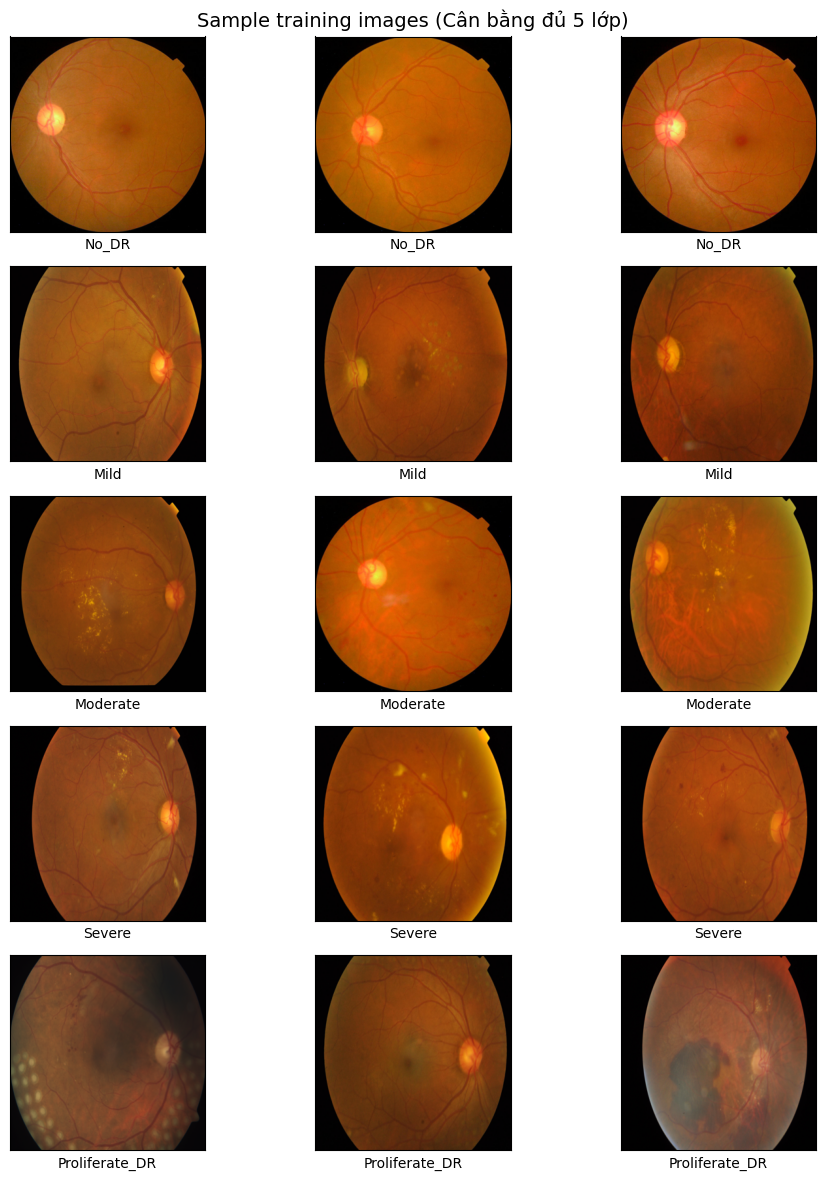

In [11]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

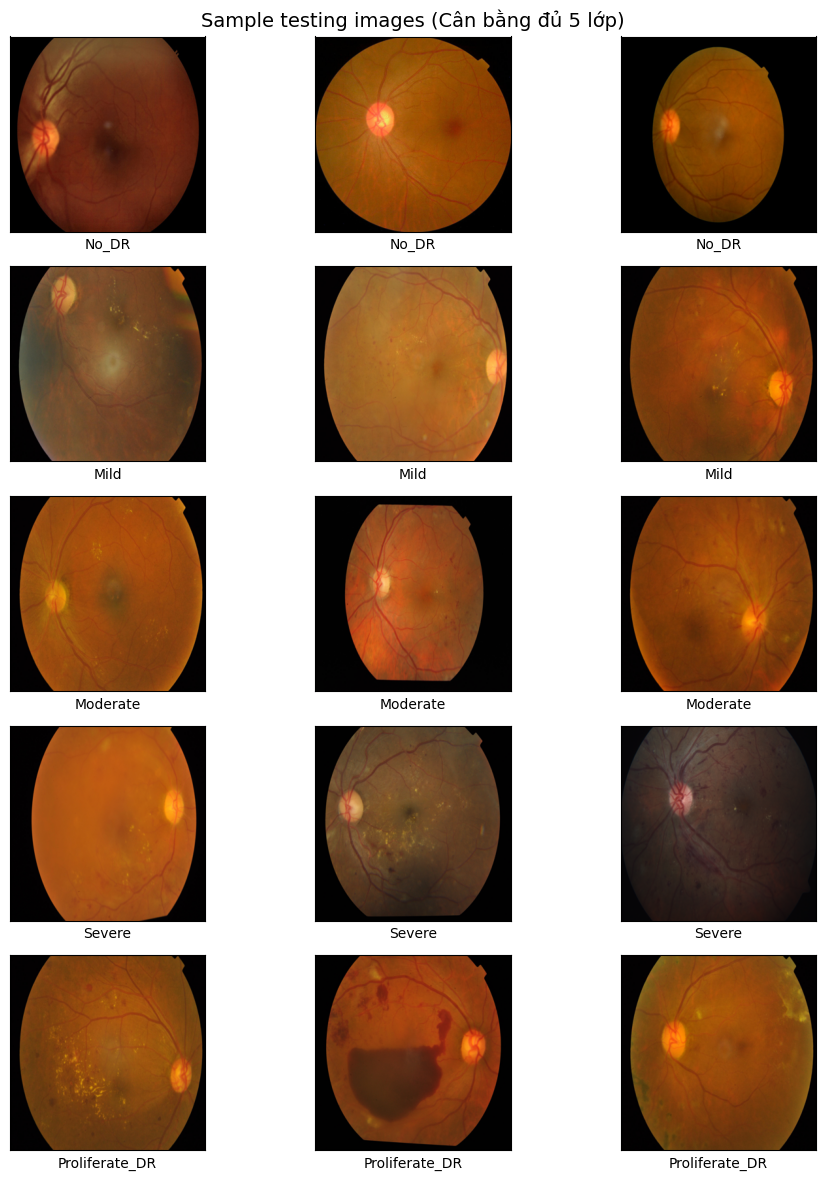

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng model ConvNeXt

In [13]:
def build_convnext_model(input_shape, num_classes):
    print("🚀 Đang khởi tạo kiến trúc: ConvNeXtTiny...")
    
    # Khởi tạo Base Model ConvNeXtTiny
    base_model = ConvNeXtTiny(weights='imagenet', 
                              include_top=False, 
                              input_shape=input_shape)
    
    # Đóng băng (Freeze) phần thân để Transfer Learning
    base_model.trainable = False
    
    # Xây dựng Classification Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    
    # ConvNeXt vốn đã học đặc trưng cực kỳ xịn, 
    # ta không cần nhồi nhét quá nhiều lớp Dense làm gì để tránh học vẹt.
    x = BatchNormalization()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x) 
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions)
    
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [14]:
model = build_convnext_model((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model.summary()

🚀 Đang khởi tạo kiến trúc: ConvNeXtTiny...


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 300, 300,  │          0 │ input_layer[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 75, 75,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 75, 75,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 75, 75,    │         96 │ convnext_tiny_st

 Total params: 28,021,349 (106.89 MB)

 Trainable params: 199,685 (780.02 KB)

 Non-trainable params: 27,821,664 (106.13 MB)

## 5. Compile & Train 

In [15]:
model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/convnext_tiny_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history = model.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785773072.731505    8024 service.cc:153] XLA service 0x7e966c0521d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785773072.731559    8024 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1785773072.976476    8024 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785773074.632177    8024 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1785773074.858678    8024 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_13640__.321
I0000 00:00:1785773075.884344    8104 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7', 9660 bytes spill stores, 8700 bytes spill loads

I0000 00:00:1785773077.868867    8109 subprocess_compilation.cc:348] ptxas war


Epoch 1: val_accuracy improved from None to 0.56545, saving model to ../../../data/models/convnext_tiny_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/convnext_tiny_aptos_200_best.keras
191/191 - 69s - 364ms/step - accuracy: 0.4574 - loss: 1.8429 - val_accuracy: 0.5654 - val_loss: 1.0550 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.56545 to 0.62827, saving model to ../../../data/models/convnext_tiny_aptos_200_best.keras

Epoch 2: finished saving model to ../../../data/models/convnext_tiny_aptos_200_best.keras
191/191 - 11s - 60ms/step - accuracy: 0.6370 - loss: 1.0368 - val_accuracy: 0.6283 - val_loss: 1.1307 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.62827 to 0.65445, saving model to ../../../data/models/convnext_tiny_aptos_200_best.keras

Epoch 3: finished saving model to ../../../data/models/convnext_tiny_aptos_200_best.keras
191/191 - 12s - 63ms/step - accuracy: 0.7313 - loss: 0.7156 - val_

## 6. Visualize Training

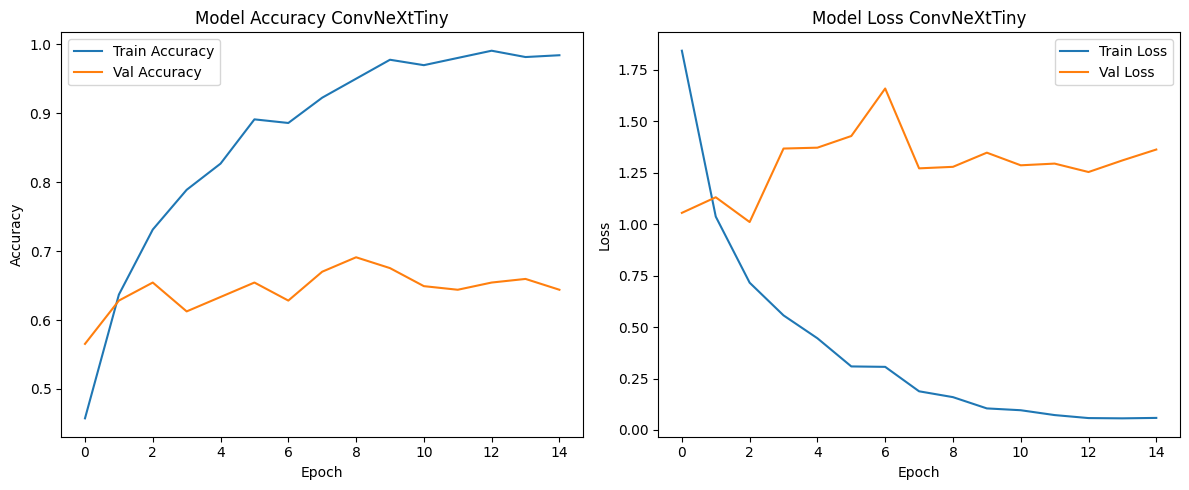

In [16]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy ConvNeXtTiny')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss ConvNeXtTiny')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [17]:
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f'Test Loss ConvNeXtTiny: {test_loss:.4f}')
print(f'Test Accuracy ConvNeXtTiny: {test_acc:.4f}') 

I0000 00:00:1785773279.847482    9616 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_13', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1785773280.224694    9617 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_13', 80 bytes spill stores, 52 bytes spill loads

I0000 00:00:1785773281.504820    9615 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7', 10744 bytes spill stores, 10648 bytes spill loads

I0000 00:00:1785773283.102336    9616 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1', 9620 bytes spill stores, 8860 bytes spill loads

I0000 00:00:1785773284.628449    9615 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_31', 9136 bytes spill stores, 8236

Test Loss ConvNeXtTiny: 0.9308
Test Accuracy ConvNeXtTiny: 0.7131
